In [9]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import pathlib
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils.class_weight import compute_class_weight
import seaborn as sns

print(f"TensorFlow: {tf.__version__}")
print(f"GPU: {len(tf.config.list_physical_devices('GPU')) > 0}")

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU memory growth enabled")
    except RuntimeError as e:
        print(e)

TensorFlow: 2.10.0
GPU: True
Physical devices cannot be modified after being initialized


In [11]:
DATA_DIR = r"C:\Users\ACER\OneDrive\Desktop\PlantVillage\PlantVillage"

IMG_SIZE = 160
BATCH_SIZE = 8
SEED = 1337
EPOCHS = 100

CLASSES = [
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy"
]
NUM_CLASSES = 3

tf.random.set_seed(SEED)
np.random.seed(SEED)

OUTPUT_ROOT = pathlib.Path("outputs_potato_improved")
OUTPUT_ROOT.mkdir(exist_ok=True)

print(f"\nMemory-Optimized Configuration:")
print(f"Data directory: {DATA_DIR}")
print(f"Image size: {IMG_SIZE}x{IMG_SIZE} (balanced for GPU memory)")
print(f"Batch size: {BATCH_SIZE} (reduced for memory)")


Memory-Optimized Configuration:
Data directory: C:\Users\ACER\OneDrive\Desktop\PlantVillage\PlantVillage
Image size: 160x160 (balanced for GPU memory)
Batch size: 8 (reduced for memory)


In [12]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    vertical_flip=True,
    brightness_range=(0.7, 1.3),
    fill_mode='reflect'
)

val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_gen = train_datagen.flow_from_directory(
    DATA_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    classes=CLASSES,
    class_mode='categorical',
    batch_size=BATCH_SIZE,
    subset='training',
    shuffle=True,
    seed=SEED
)

val_gen = val_datagen.flow_from_directory(
    DATA_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    classes=CLASSES,
    class_mode='categorical',
    batch_size=BATCH_SIZE,
    subset='validation',
    shuffle=False,
    seed=SEED
)

print("\nClass indices:")
print(f"Train: {train_gen.class_indices}")
print(f"Val:   {val_gen.class_indices}")

assert train_gen.class_indices == val_gen.class_indices, "Class order mismatch!"

print(f"\nData split:")
print(f"Training samples: {train_gen.samples}")
print(f"Validation samples: {val_gen.samples}")


Found 1722 images belonging to 3 classes.
Found 430 images belonging to 3 classes.

Class indices:
Train: {'Potato___Early_blight': 0, 'Potato___Late_blight': 1, 'Potato___healthy': 2}
Val:   {'Potato___Early_blight': 0, 'Potato___Late_blight': 1, 'Potato___healthy': 2}

Data split:
Training samples: 1722
Validation samples: 430


In [13]:
train_labels = train_gen.classes

class_weights = compute_class_weight(
    'balanced',
    classes=np.arange(NUM_CLASSES),
    y=train_labels
)
class_weight_dict = dict(enumerate(class_weights))

print("\nClass weights:")
for i, class_name in enumerate(CLASSES):
    print(f"{class_name}: {class_weight_dict[i]:.4f}")


Class weights:
Potato___Early_blight: 0.7175
Potato___Late_blight: 0.7175
Potato___healthy: 4.7049


In [14]:
def get_improved_cnn():
    """Memory-efficient improved CNN"""
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    
    # Block 1
    x = layers.Conv2D(48, 3, padding="same")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.2)(x)
    
    # Block 2
    x = layers.Conv2D(96, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.25)(x)
    
    # Block 3
    x = layers.Conv2D(192, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.3)(x)
    
    # Block 4
    x = layers.Conv2D(256, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.GlobalAveragePooling2D()(x)
    
    # Dense head
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(256, activation="relu", kernel_regularizer=keras.regularizers.l2(0.001))(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation="relu", kernel_regularizer=keras.regularizers.l2(0.001))(x)
    x = layers.Dropout(0.3)(x)
    
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    
    return keras.Model(inputs, outputs, name="ImprovedPotatoCNN")

model = get_improved_cnn()
model.summary()

print(f"\nModel parameters: {model.count_params():,}")
print("Optimizations:")
print("- Memory-efficient filter sizes (48->96->192->256)")
print("- 160x160 input (balanced quality and memory)")
print("- Batch size 8 (fits in GPU memory)")
print("- Batch normalization for stable training")
print("- L2 regularization to prevent overfitting")

Model: "ImprovedPotatoCNN"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 160, 160, 3)]     0         
                                                                 
 conv2d_6 (Conv2D)           (None, 160, 160, 48)      1344      
                                                                 
 batch_normalization_6 (Batc  (None, 160, 160, 48)     192       
 hNormalization)                                                 
                                                                 
 activation_6 (Activation)   (None, 160, 160, 48)      0         
                                                                 
 max_pooling2d_3 (MaxPooling  (None, 80, 80, 48)       0         
 2D)                                                             
                                                                 
 dropout_6 (Dropout)         (None, 80, 80, 48)  

In [15]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=5e-5),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)

print("Model compiled with label smoothing and low learning rate")

Model compiled with label smoothing and low learning rate


In [16]:
checkpoint = keras.callbacks.ModelCheckpoint(
    OUTPUT_ROOT / "best_model.h5",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=7,
    min_lr=1e-7,
    verbose=1
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

csv_logger = keras.callbacks.CSVLogger(
    OUTPUT_ROOT / 'training_log.csv',
    separator=',',
    append=False
)

callbacks = [checkpoint, reduce_lr, early_stop, csv_logger]

print("Callbacks configured")

Callbacks configured


In [17]:
print("\nStarting training...\n")

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=callbacks,
    class_weight=class_weight_dict,
    verbose=1
)

print("\nTraining completed")


Starting training...

Epoch 1/100
216/216 [==============================] - ETA: 0s - loss: 1.5437 - accuracy: 0.4930
Epoch 1: val_accuracy improved from -inf to 0.46512, saving model to outputs_potato_improved\best_model.h5
216/216 [==============================] - 21s 86ms/step - loss: 1.5437 - accuracy: 0.4930 - val_loss: 1.6306 - val_accuracy: 0.4651 - lr: 5.0000e-05
Epoch 2/100
216/216 [==============================] - ETA: 0s - loss: 1.3816 - accuracy: 0.5465
Epoch 2: val_accuracy did not improve from 0.46512
216/216 [==============================] - 18s 85ms/step - loss: 1.3816 - accuracy: 0.5465 - val_loss: 1.5058 - val_accuracy: 0.4651 - lr: 5.0000e-05
Epoch 3/100
216/216 [==============================] - ETA: 0s - loss: 1.2742 - accuracy: 0.6458
Epoch 3: val_accuracy improved from 0.46512 to 0.50465, saving model to outputs_potato_improved\best_model.h5
216/216 [==============================] - 18s 84ms/step - loss: 1.2742 - accuracy: 0.6458 - val_loss: 1.4660 - val_ac

In [18]:
best_model = keras.models.load_model(OUTPUT_ROOT / 'best_model.h5')
print("Best model loaded")

Best model loaded


In [19]:
val_gen.reset()

val_loss, val_acc = best_model.evaluate(val_gen, verbose=1)

print(f"\nValidation results:")
print(f"Loss: {val_loss:.4f}")
print(f"Accuracy: {val_acc:.4f} ({val_acc*100:.2f}%)")

54/54 [==============================] - 1s 18ms/step - loss: 0.6599 - accuracy: 0.9674

Validation results:
Loss: 0.6599
Accuracy: 0.9674 (96.74%)


In [20]:
val_gen.reset()

predictions = best_model.predict(val_gen, verbose=1)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = val_gen.classes

print(f"\nGenerated {len(predictions)} predictions")

54/54 [==============================] - 1s 17ms/step

Generated 430 predictions


In [21]:
print("\nClassification Report:\n")
report = classification_report(true_classes, predicted_classes,
                               target_names=CLASSES, digits=4, output_dict=True)
print(classification_report(true_classes, predicted_classes,
                          target_names=CLASSES, digits=4))

print("\nPer-class performance:")
for i, class_name in enumerate(CLASSES):
    class_mask = true_classes == i
    if class_mask.sum() > 0:
        class_correct = (predicted_classes[class_mask] == true_classes[class_mask]).sum()
        class_total = class_mask.sum()
        class_acc = class_correct / class_total
        
        print(f"\n{class_name}")
        print(f"  Samples: {class_total}")
        print(f"  Correct: {class_correct}")
        print(f"  Accuracy: {class_acc*100:.2f}%")
        print(f"  Precision: {report[class_name]['precision']:.4f}")
        print(f"  Recall: {report[class_name]['recall']:.4f}")
        print(f"  F1-score: {report[class_name]['f1-score']:.4f}")


Classification Report:

                       precision    recall  f1-score   support

Potato___Early_blight     1.0000    0.9700    0.9848       200
 Potato___Late_blight     0.9697    0.9600    0.9648       200
     Potato___healthy     0.7895    1.0000    0.8824        30

             accuracy                         0.9674       430
            macro avg     0.9197    0.9767    0.9440       430
         weighted avg     0.9712    0.9674    0.9683       430


Per-class performance:

Potato___Early_blight
  Samples: 200
  Correct: 194
  Accuracy: 97.00%
  Precision: 1.0000
  Recall: 0.9700
  F1-score: 0.9848

Potato___Late_blight
  Samples: 200
  Correct: 192
  Accuracy: 96.00%
  Precision: 0.9697
  Recall: 0.9600
  F1-score: 0.9648

Potato___healthy
  Samples: 30
  Correct: 30
  Accuracy: 100.00%
  Precision: 0.7895
  Recall: 1.0000
  F1-score: 0.8824



Confusion matrix saved to: outputs_potato_improved\confusion_matrix_improved.png


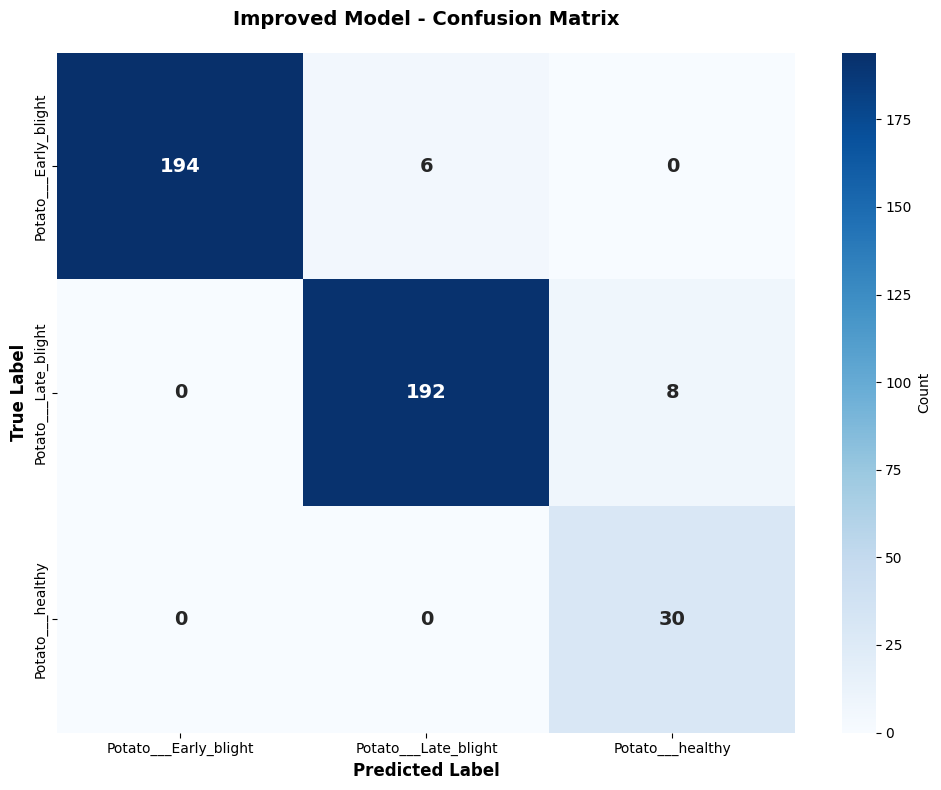


Confusion analysis:
Early_blight: 194/200 (97.0%)
Late_blight: 192/200 (96.0%)
Healthy: 30/30 (100.0%)


In [22]:
cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES,
            yticklabels=CLASSES,
            cbar_kws={'label': 'Count'},
            annot_kws={'size': 14, 'weight': 'bold'})

plt.title('Improved Model - Confusion Matrix',
          fontsize=14, fontweight='bold', pad=20)
plt.ylabel('True Label', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
plt.tight_layout()

cm_path = OUTPUT_ROOT / 'confusion_matrix_improved.png'
plt.savefig(cm_path, dpi=150, bbox_inches='tight')
print(f"\nConfusion matrix saved to: {cm_path}")
plt.show()

print("\nConfusion analysis:")
print(f"Early_blight: {cm[0,0]}/{cm[0].sum()} ({cm[0,0]/cm[0].sum()*100:.1f}%)")
print(f"Late_blight: {cm[1,1]}/{cm[1].sum()} ({cm[1,1]/cm[1].sum()*100:.1f}%)")
print(f"Healthy: {cm[2,2]}/{cm[2].sum()} ({cm[2,2]/cm[2].sum()*100:.1f}%)")


Training history saved to: outputs_potato_improved\training_history_improved.png


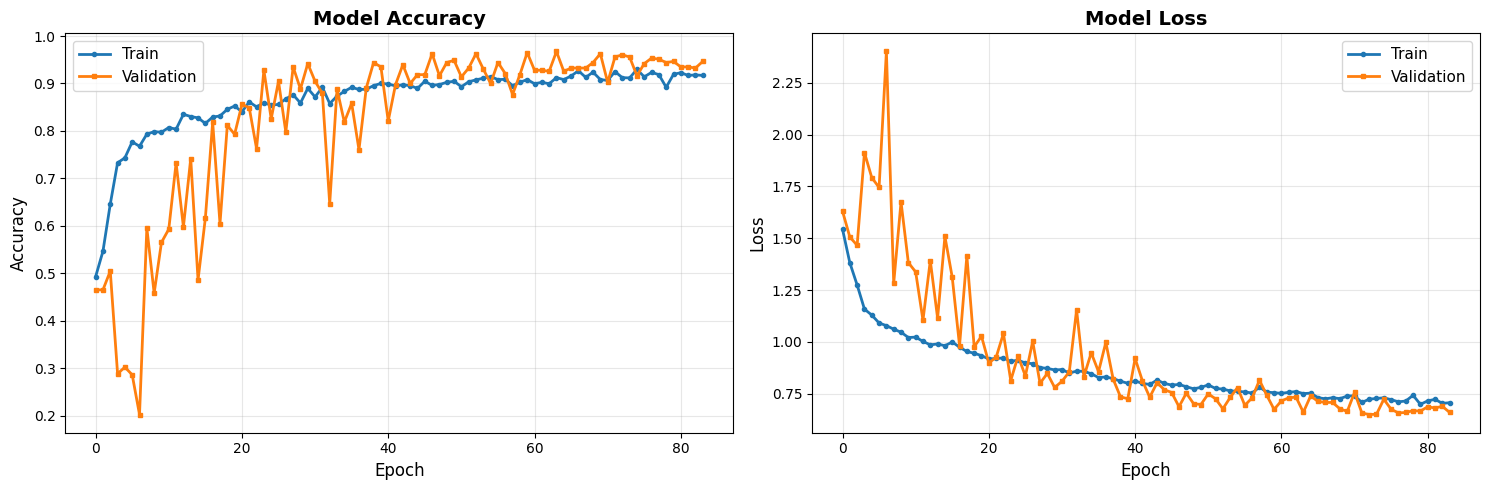

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

ax1.plot(history.history['accuracy'], label='Train', linewidth=2, marker='o', markersize=3)
ax1.plot(history.history['val_accuracy'], label='Validation', linewidth=2, marker='s', markersize=3)
ax1.set_title('Model Accuracy', fontsize=14, fontweight='bold')
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Accuracy', fontsize=12)
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)

ax2.plot(history.history['loss'], label='Train', linewidth=2, marker='o', markersize=3)
ax2.plot(history.history['val_loss'], label='Validation', linewidth=2, marker='s', markersize=3)
ax2.set_title('Model Loss', fontsize=14, fontweight='bold')
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Loss', fontsize=12)
ax2.legend(fontsize=11)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
history_path = OUTPUT_ROOT / 'training_history_improved.png'
plt.savefig(history_path, dpi=150, bbox_inches='tight')
print(f"\nTraining history saved to: {history_path}")
plt.show()

In [24]:
final_train_acc = history.history['accuracy'][-1]
final_val_acc = history.history['val_accuracy'][-1]
gap = final_train_acc - final_val_acc

print("\nFinal Summary")
print("-" * 60)
print(f"Image size: {IMG_SIZE}x{IMG_SIZE}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Model parameters: {model.count_params():,}")
print(f"\nFinal training accuracy: {final_train_acc*100:.2f}%")
print(f"Final validation accuracy: {final_val_acc*100:.2f}%")
print(f"Best validation accuracy: {val_acc*100:.2f}%")
print(f"Overfitting gap: {gap*100:.2f}%")
print(f"\nOutputs saved in: {OUTPUT_ROOT.absolute()}")
print("\nTraining complete!")


Final Summary
------------------------------------------------------------
Image size: 160x160
Batch size: 8
Model parameters: 753,059

Final training accuracy: 91.70%
Final validation accuracy: 94.65%
Best validation accuracy: 96.74%
Overfitting gap: -2.96%

Outputs saved in: c:\Users\ACER\OneDrive\Desktop\PlantVillage\outputs_potato_improved

Training complete!


In [25]:
final_train_acc = history.history['accuracy'][-1]
final_val_acc = history.history['val_accuracy'][-1]
gap = final_train_acc - final_val_acc

best_val_acc = max(history.history['val_accuracy'])
best_epoch = history.history['val_accuracy'].index(best_val_acc) + 1

print("\nOverfitting analysis:")
print(f"Final training accuracy: {final_train_acc*100:.2f}%")
print(f"Final validation accuracy: {final_val_acc*100:.2f}%")
print(f"Accuracy gap: {gap*100:.2f}%")
print(f"\nBest validation accuracy: {best_val_acc*100:.2f}% (Epoch {best_epoch})")

if gap < 0.05:
    print("Status: Excellent generalization")
elif gap < 0.10:
    print("Status: Good generalization")
elif gap < 0.15:
    print("Status: Mild overfitting")
else:
    print("Status: Moderate overfitting (expected for small dataset)")



Overfitting analysis:
Final training accuracy: 91.70%
Final validation accuracy: 94.65%
Accuracy gap: -2.96%

Best validation accuracy: 96.74% (Epoch 64)
Status: Excellent generalization


In [26]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import pathlib
from sklearn.metrics import (
    classification_report, 
    confusion_matrix, 
    accuracy_score,
    precision_recall_fscore_support,
    roc_auc_score,
    roc_curve
)
from sklearn.preprocessing import label_binarize
import seaborn as sns

# Paths
MODEL_PATH = r"outputs_potato_improved\best_model.h5"
OUTER_DIR = r"C:\Users\ACER\OneDrive\Desktop\PlantVillage"
OUTPUT_DIR = pathlib.Path("inference_results")
OUTPUT_DIR.mkdir(exist_ok=True)

# Classes
CLASSES = [
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy"
]
NUM_CLASSES = 3
IMG_SIZE = 160

print("Loading best trained model...")
model = keras.models.load_model(MODEL_PATH)
print(f"Model loaded successfully")
print(f"Model parameters: {model.count_params():,}")

Loading best trained model...
Model loaded successfully
Model parameters: 753,059


In [27]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Create test data generator (no augmentation, no split)
test_datagen = ImageDataGenerator(rescale=1./255)

test_gen = test_datagen.flow_from_directory(
    OUTER_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    classes=CLASSES,
    class_mode='categorical',
    batch_size=32,
    shuffle=False
)

print(f"\nTest dataset statistics:")
print(f"Total samples: {test_gen.samples}")
print(f"Classes: {test_gen.class_indices}")
print(f"Batches: {len(test_gen)}")

# Get class distribution
unique, counts = np.unique(test_gen.classes, return_counts=True)
print(f"\nClass distribution:")
for class_idx, count in zip(unique, counts):
    print(f"  {CLASSES[class_idx]}: {count} images")

Found 2152 images belonging to 3 classes.

Test dataset statistics:
Total samples: 2152
Classes: {'Potato___Early_blight': 0, 'Potato___Late_blight': 1, 'Potato___healthy': 2}
Batches: 68

Class distribution:
  Potato___Early_blight: 1000 images
  Potato___Late_blight: 1000 images
  Potato___healthy: 152 images


In [28]:
print("\nGenerating predictions on entire dataset...")

# Reset generator
test_gen.reset()

# Get predictions
predictions = model.predict(test_gen, verbose=1)
predicted_classes = np.argmax(predictions, axis=1)
predicted_probs = np.max(predictions, axis=1)
true_classes = test_gen.classes

print(f"\nPredictions generated for {len(predictions)} images")


Generating predictions on entire dataset...
68/68 [==============================] - 37s 539ms/step

Predictions generated for 2152 images


In [29]:
print("\n" + "="*80)
print("OVERALL PERFORMANCE METRICS")
print("="*80)

# Overall accuracy
overall_acc = accuracy_score(true_classes, predicted_classes)
print(f"\nOverall Accuracy: {overall_acc:.4f} ({overall_acc*100:.2f}%)")

# Precision, Recall, F1 for each class
precision, recall, f1, support = precision_recall_fscore_support(
    true_classes, 
    predicted_classes, 
    average=None
)

print(f"\nMacro-averaged metrics:")
macro_precision = precision.mean()
macro_recall = recall.mean()
macro_f1 = f1.mean()
print(f"  Precision: {macro_precision:.4f}")
print(f"  Recall: {macro_recall:.4f}")
print(f"  F1-Score: {macro_f1:.4f}")

print(f"\nWeighted-averaged metrics:")
weighted_precision, weighted_recall, weighted_f1, _ = precision_recall_fscore_support(
    true_classes, 
    predicted_classes, 
    average='weighted'
)
print(f"  Precision: {weighted_precision:.4f}")
print(f"  Recall: {weighted_recall:.4f}")
print(f"  F1-Score: {weighted_f1:.4f}")


OVERALL PERFORMANCE METRICS

Overall Accuracy: 0.9647 (96.47%)

Macro-averaged metrics:
  Precision: 0.9195
  Recall: 0.9747
  F1-Score: 0.9431

Weighted-averaged metrics:
  Precision: 0.9683
  Recall: 0.9647
  F1-Score: 0.9655


In [30]:
print("\n" + "="*80)
print("DETAILED CLASSIFICATION REPORT")
print("="*80 + "\n")

report = classification_report(
    true_classes, 
    predicted_classes,
    target_names=CLASSES, 
    digits=4,
    output_dict=True
)

print(classification_report(
    true_classes, 
    predicted_classes,
    target_names=CLASSES, 
    digits=4
))

# Save report to CSV
report_df = pd.DataFrame(report).transpose()
report_path = OUTPUT_DIR / 'classification_report.csv'
report_df.to_csv(report_path)
print(f"\nClassification report saved to: {report_path}")



DETAILED CLASSIFICATION REPORT

                       precision    recall  f1-score   support

Potato___Early_blight     0.9979    0.9630    0.9802      1000
 Potato___Late_blight     0.9649    0.9610    0.9629      1000
     Potato___healthy     0.7958    1.0000    0.8863       152

             accuracy                         0.9647      2152
            macro avg     0.9195    0.9747    0.9431      2152
         weighted avg     0.9683    0.9647    0.9655      2152


Classification report saved to: inference_results\classification_report.csv


In [31]:
print("\n" + "="*80)
print("PER-CLASS DETAILED METRICS")
print("="*80)

results_data = []

for i, class_name in enumerate(CLASSES):
    class_mask = true_classes == i
    class_total = class_mask.sum()
    
    if class_total > 0:
        class_preds = predicted_classes[class_mask]
        class_true = true_classes[class_mask]
        class_probs = predicted_probs[class_mask]
        
        # Metrics
        class_correct = (class_preds == class_true).sum()
        class_acc = class_correct / class_total
        
        # Confidence stats
        avg_confidence = class_probs.mean()
        min_confidence = class_probs.min()
        max_confidence = class_probs.max()
        
        print(f"\n{class_name}")
        print(f"  Total samples: {class_total}")
        print(f"  Correct predictions: {class_correct}")
        print(f"  Accuracy: {class_acc*100:.2f}%")
        print(f"  Precision: {report[class_name]['precision']:.4f}")
        print(f"  Recall: {report[class_name]['recall']:.4f}")
        print(f"  F1-Score: {report[class_name]['f1-score']:.4f}")
        print(f"  Avg confidence: {avg_confidence:.4f}")
        print(f"  Min confidence: {min_confidence:.4f}")
        print(f"  Max confidence: {max_confidence:.4f}")
        
        results_data.append({
            'Class': class_name,
            'Total_Samples': class_total,
            'Correct': class_correct,
            'Accuracy': class_acc,
            'Precision': report[class_name]['precision'],
            'Recall': report[class_name]['recall'],
            'F1_Score': report[class_name]['f1-score'],
            'Avg_Confidence': avg_confidence,
            'Min_Confidence': min_confidence,
            'Max_Confidence': max_confidence
        })

# Save per-class metrics
results_df = pd.DataFrame(results_data)
results_path = OUTPUT_DIR / 'per_class_metrics.csv'
results_df.to_csv(results_path, index=False)
print(f"\n\nPer-class metrics saved to: {results_path}")



PER-CLASS DETAILED METRICS

Potato___Early_blight
  Total samples: 1000
  Correct predictions: 963
  Accuracy: 96.30%
  Precision: 0.9979
  Recall: 0.9630
  F1-Score: 0.9802
  Avg confidence: 0.8920
  Min confidence: 0.4279
  Max confidence: 0.9949

Potato___Late_blight
  Total samples: 1000
  Correct predictions: 961
  Accuracy: 96.10%
  Precision: 0.9649
  Recall: 0.9610
  F1-Score: 0.9629
  Avg confidence: 0.9190
  Min confidence: 0.4965
  Max confidence: 0.9976

Potato___healthy
  Total samples: 152
  Correct predictions: 152
  Accuracy: 100.00%
  Precision: 0.7958
  Recall: 1.0000
  F1-Score: 0.8863
  Avg confidence: 0.9414
  Min confidence: 0.5696
  Max confidence: 0.9823


Per-class metrics saved to: inference_results\per_class_metrics.csv



CONFUSION MATRIX

Confusion matrix saved to: inference_results\confusion_matrix_detailed.png


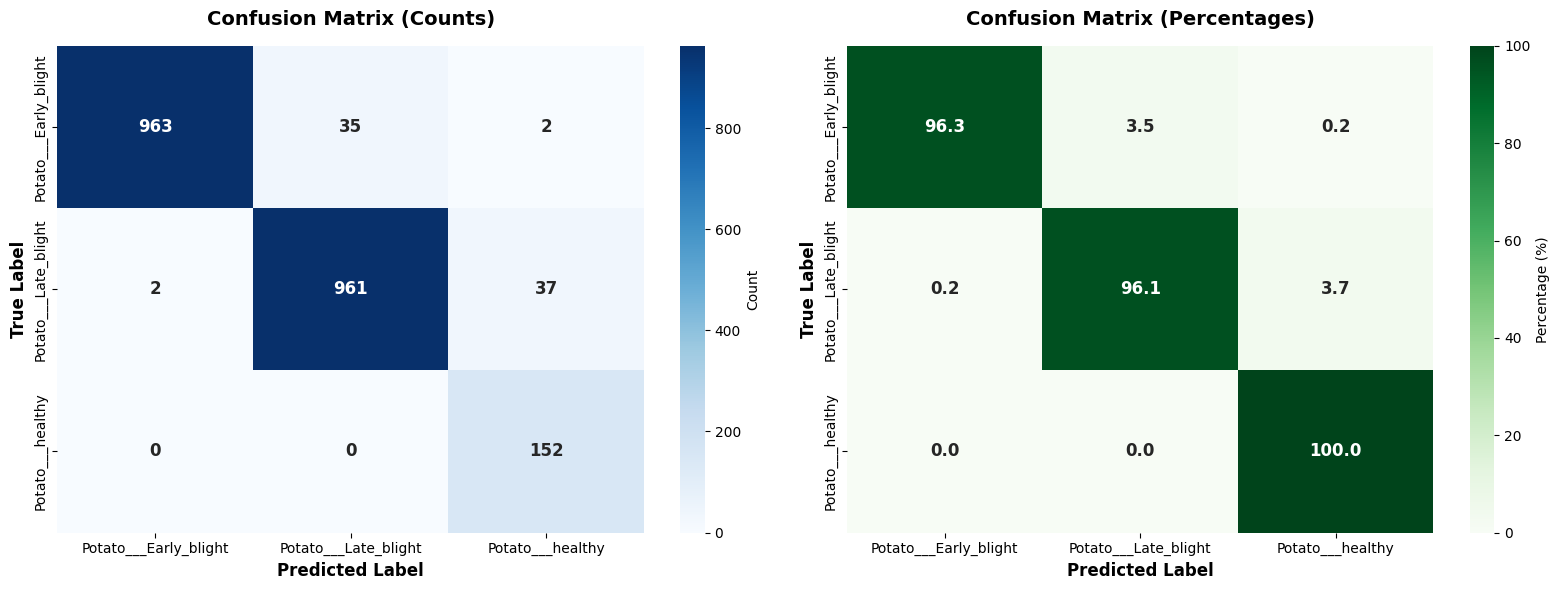


Confusion Matrix Analysis:

Potato___Early_blight:
  Correctly classified: 963/1000 (96.30%)
  Misclassified as Potato___Late_blight: 35 (3.50%)
  Misclassified as Potato___healthy: 2 (0.20%)

Potato___Late_blight:
  Correctly classified: 961/1000 (96.10%)
  Misclassified as Potato___Early_blight: 2 (0.20%)
  Misclassified as Potato___healthy: 37 (3.70%)

Potato___healthy:
  Correctly classified: 152/152 (100.00%)


In [32]:
print("\n" + "="*80)
print("CONFUSION MATRIX")
print("="*80)

cm = confusion_matrix(true_classes, predicted_classes)

# Calculate percentages
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

# Create figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Confusion matrix with counts
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES,
            yticklabels=CLASSES,
            cbar_kws={'label': 'Count'},
            annot_kws={'size': 12, 'weight': 'bold'},
            ax=ax1)
ax1.set_title('Confusion Matrix (Counts)', fontsize=14, fontweight='bold', pad=15)
ax1.set_ylabel('True Label', fontsize=12, fontweight='bold')
ax1.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')

# Confusion matrix with percentages
sns.heatmap(cm_percent, annot=True, fmt='.1f', cmap='Greens',
            xticklabels=CLASSES,
            yticklabels=CLASSES,
            cbar_kws={'label': 'Percentage (%)'},
            annot_kws={'size': 12, 'weight': 'bold'},
            ax=ax2)
ax2.set_title('Confusion Matrix (Percentages)', fontsize=14, fontweight='bold', pad=15)
ax2.set_ylabel('True Label', fontsize=12, fontweight='bold')
ax2.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')

plt.tight_layout()
cm_path = OUTPUT_DIR / 'confusion_matrix_detailed.png'
plt.savefig(cm_path, dpi=150, bbox_inches='tight')
print(f"\nConfusion matrix saved to: {cm_path}")
plt.show()

# Print confusion matrix analysis
print("\nConfusion Matrix Analysis:")
for i, class_name in enumerate(CLASSES):
    correct = cm[i, i]
    total = cm[i].sum()
    accuracy = correct / total * 100 if total > 0 else 0
    print(f"\n{class_name}:")
    print(f"  Correctly classified: {correct}/{total} ({accuracy:.2f}%)")
    
    # Find misclassifications
    for j, other_class in enumerate(CLASSES):
        if i != j and cm[i, j] > 0:
            print(f"  Misclassified as {other_class}: {cm[i, j]} ({cm[i, j]/total*100:.2f}%)")

# Save confusion matrix
cm_df = pd.DataFrame(cm, index=CLASSES, columns=CLASSES)
cm_df.to_csv(OUTPUT_DIR / 'confusion_matrix.csv')



ROC CURVES AND AUC SCORES
Potato___Early_blight:
  AUC: 0.9997
Potato___Late_blight:
  AUC: 0.9946
Potato___healthy:
  AUC: 0.9995

ROC curves saved to: inference_results\roc_curves.png


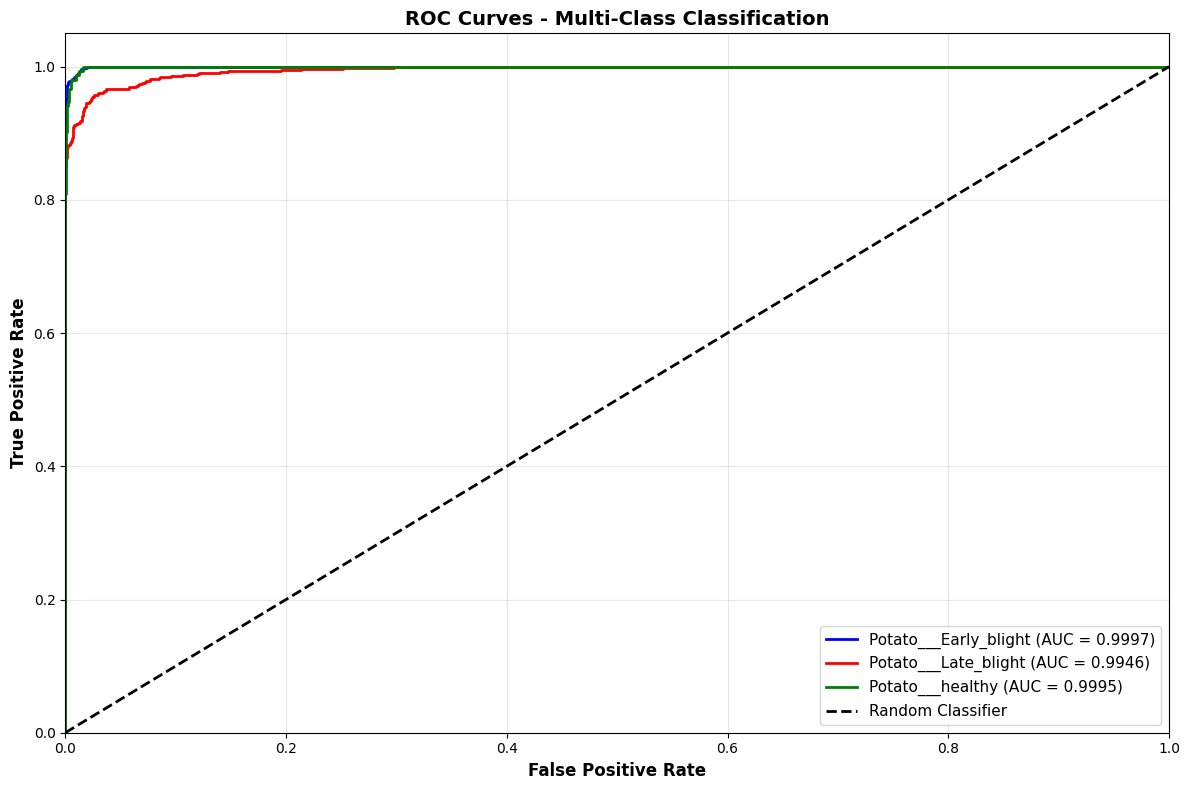


Macro-average AUC: 0.9979


In [33]:
print("\n" + "="*80)
print("ROC CURVES AND AUC SCORES")
print("="*80)

# Binarize labels for multi-class ROC
y_true_bin = label_binarize(true_classes, classes=[0, 1, 2])

# Calculate ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

plt.figure(figsize=(12, 8))

colors = ['blue', 'red', 'green']
for i, (class_name, color) in enumerate(zip(CLASSES, colors)):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], predictions[:, i])
    roc_auc[i] = roc_auc_score(y_true_bin[:, i], predictions[:, i])
    
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'{class_name} (AUC = {roc_auc[i]:.4f})')
    
    print(f"{class_name}:")
    print(f"  AUC: {roc_auc[i]:.4f}")

# Plot diagonal
plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Classifier')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=12, fontweight='bold')
plt.title('ROC Curves - Multi-Class Classification', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()

roc_path = OUTPUT_DIR / 'roc_curves.png'
plt.savefig(roc_path, dpi=150, bbox_inches='tight')
print(f"\nROC curves saved to: {roc_path}")
plt.show()

# Calculate macro and micro average AUC
macro_auc = np.mean(list(roc_auc.values()))
print(f"\nMacro-average AUC: {macro_auc:.4f}")



PREDICTION CONFIDENCE ANALYSIS

Confidence distribution saved to: inference_results\confidence_distribution.png


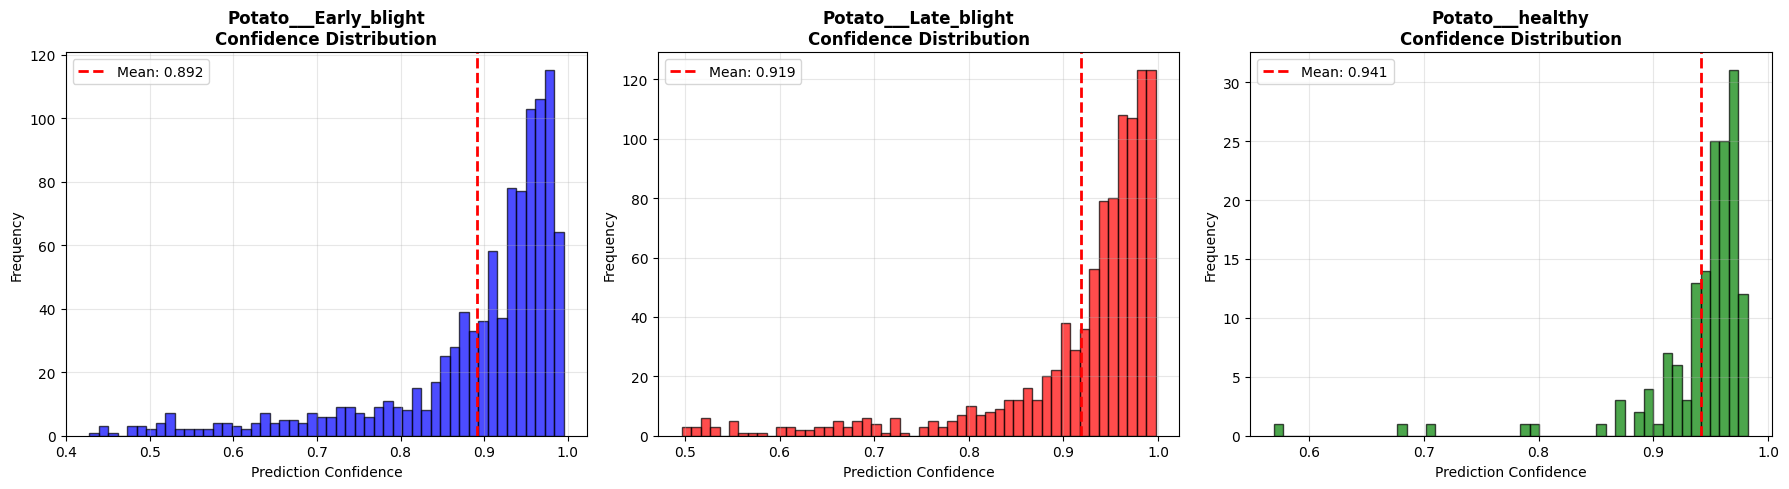

In [34]:
print("\n" + "="*80)
print("PREDICTION CONFIDENCE ANALYSIS")
print("="*80)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (class_name, ax) in enumerate(zip(CLASSES, axes)):
    class_mask = true_classes == i
    class_confidences = predicted_probs[class_mask]
    
    ax.hist(class_confidences, bins=50, alpha=0.7, color=['blue', 'red', 'green'][i], edgecolor='black')
    ax.set_title(f'{class_name}\nConfidence Distribution', fontsize=12, fontweight='bold')
    ax.set_xlabel('Prediction Confidence', fontsize=10)
    ax.set_ylabel('Frequency', fontsize=10)
    ax.axvline(class_confidences.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {class_confidences.mean():.3f}')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
conf_path = OUTPUT_DIR / 'confidence_distribution.png'
plt.savefig(conf_path, dpi=150, bbox_inches='tight')
print(f"\nConfidence distribution saved to: {conf_path}")
plt.show()

In [35]:
print("\n" + "="*80)
print("SAVING DETAILED PREDICTIONS")
print("="*80)

# Get file paths
file_paths = test_gen.filepaths

# Create detailed predictions dataframe
predictions_df = pd.DataFrame({
    'file_path': file_paths,
    'true_label': true_classes,
    'predicted_label': predicted_classes,
    'true_class': [CLASSES[i] for i in true_classes],
    'predicted_class': [CLASSES[i] for i in predicted_classes],
    'correct': true_classes == predicted_classes,
    'confidence': predicted_probs,
    'prob_early_blight': predictions[:, 0],
    'prob_late_blight': predictions[:, 1],
    'prob_healthy': predictions[:, 2]
})

# Save to CSV
pred_path = OUTPUT_DIR / 'all_predictions.csv'
predictions_df.to_csv(pred_path, index=False)
print(f"\nAll predictions saved to: {pred_path}")

# Show sample misclassifications
misclassified = predictions_df[predictions_df['correct'] == False]
if len(misclassified) > 0:
    print(f"\nTotal misclassifications: {len(misclassified)}")
    print(f"\nSample misclassifications (first 10):")
    print(misclassified[['file_path', 'true_class', 'predicted_class', 'confidence']].head(10))
    
    # Save misclassifications
    misc_path = OUTPUT_DIR / 'misclassifications.csv'
    misclassified.to_csv(misc_path, index=False)
    print(f"\nAll misclassifications saved to: {misc_path}")
else:
    print("\nNo misclassifications! Perfect accuracy!")



SAVING DETAILED PREDICTIONS

All predictions saved to: inference_results\all_predictions.csv

Total misclassifications: 76

Sample misclassifications (first 10):
                                             file_path             true_class  \
42   C:\Users\ACER\OneDrive\Desktop\PlantVillage\Po...  Potato___Early_blight   
53   C:\Users\ACER\OneDrive\Desktop\PlantVillage\Po...  Potato___Early_blight   
116  C:\Users\ACER\OneDrive\Desktop\PlantVillage\Po...  Potato___Early_blight   
147  C:\Users\ACER\OneDrive\Desktop\PlantVillage\Po...  Potato___Early_blight   
171  C:\Users\ACER\OneDrive\Desktop\PlantVillage\Po...  Potato___Early_blight   
187  C:\Users\ACER\OneDrive\Desktop\PlantVillage\Po...  Potato___Early_blight   
203  C:\Users\ACER\OneDrive\Desktop\PlantVillage\Po...  Potato___Early_blight   
221  C:\Users\ACER\OneDrive\Desktop\PlantVillage\Po...  Potato___Early_blight   
222  C:\Users\ACER\OneDrive\Desktop\PlantVillage\Po...  Potato___Early_blight   
227  C:\Users\ACER\OneDrive

In [36]:
print("\n" + "="*80)
print("FINAL EVALUATION SUMMARY")
print("="*80)

print(f"\nDataset: {test_gen.samples} potato disease images")
print(f"Classes: {NUM_CLASSES}")
print(f"  - {CLASSES[0]}: {(true_classes == 0).sum()} images")
print(f"  - {CLASSES[1]}: {(true_classes == 1).sum()} images")
print(f"  - {CLASSES[2]}: {(true_classes == 2).sum()} images")

print(f"\nModel Architecture: Improved Custom CNN")
print(f"Parameters: {model.count_params():,}")
print(f"Image Size: {IMG_SIZE}x{IMG_SIZE}")

print(f"\nOverall Performance:")
print(f"  Accuracy: {overall_acc*100:.2f}%")
print(f"  Macro F1-Score: {macro_f1:.4f}")
print(f"  Weighted F1-Score: {weighted_f1:.4f}")
print(f"  Macro AUC: {macro_auc:.4f}")

print(f"\nPer-Class Performance:")
for i, class_name in enumerate(CLASSES):
    class_mask = true_classes == i
    class_acc = (predicted_classes[class_mask] == true_classes[class_mask]).mean()
    print(f"  {class_name}: {class_acc*100:.2f}%")

print(f"\nAll results saved in: {OUTPUT_DIR.absolute()}")
print("Files generated:")
print("  - classification_report.csv")
print("  - per_class_metrics.csv")
print("  - confusion_matrix.csv")
print("  - confusion_matrix_detailed.png")
print("  - roc_curves.png")
print("  - confidence_distribution.png")
print("  - all_predictions.csv")
print("  - misclassifications.csv")

print("\n" + "="*80)
print("EVALUATION COMPLETE!")
print("="*80)



FINAL EVALUATION SUMMARY

Dataset: 2152 potato disease images
Classes: 3
  - Potato___Early_blight: 1000 images
  - Potato___Late_blight: 1000 images
  - Potato___healthy: 152 images

Model Architecture: Improved Custom CNN
Parameters: 753,059
Image Size: 160x160

Overall Performance:
  Accuracy: 96.47%
  Macro F1-Score: 0.9431
  Weighted F1-Score: 0.9655
  Macro AUC: 0.9979

Per-Class Performance:
  Potato___Early_blight: 96.30%
  Potato___Late_blight: 96.10%
  Potato___healthy: 100.00%

All results saved in: c:\Users\ACER\OneDrive\Desktop\PlantVillage\inference_results
Files generated:
  - classification_report.csv
  - per_class_metrics.csv
  - confusion_matrix.csv
  - confusion_matrix_detailed.png
  - roc_curves.png
  - confidence_distribution.png
  - all_predictions.csv
  - misclassifications.csv

EVALUATION COMPLETE!
